# Multiclass_EfficientNetB3_Stage2_V1: Malignant Subtype Classification (mel / bcc / akiec)

**Stage 2** of the hierarchical pipeline documented in the project handover (Section 17). Trained
only on lesions already predicted **Malignant** by the Stage 1 Soft Voting Ensemble
(`DenseNet121 + DINOv2 + EfficientNet-B3`) - this notebook classifies *which* malignant subtype:
melanoma (`mel`), basal cell carcinoma (`bcc`), or actinic keratosis (`akiec`).

**Does NOT touch Stage 1 in any way**: reads Stage 1's already-produced, already-split
`train.csv` / `val.csv` / `test.csv` and filters them down to the 3 malignant classes only - no
new split, no re-preprocessing, no change to any Stage 1 file.

**Adapted from `Binary_EfficientNetB3_Baseline_V2.ipynb`** (the strongest standalone Stage 1
backbone). Every component that is not inherently binary-specific is reused unchanged: data
loading, image path resolution, the EfficientNet-B3 backbone and its fine-tuning strategy, TTA,
logging, plotting conventions, and the verified/aligned/sorted predictions-saving pattern.
Components that *are* inherently binary-specific were rewritten for 3 classes - see the notebook
body for a explanatory markdown cell directly above each one.

**Explicitly NOT done here** (per project decision): no probability calibration - this notebook
reports raw softmax probabilities directly. No decision threshold is searched or applied - the
predicted class is simply `argmax` over the 3 softmax probabilities.


## 1. Imports

In [1]:
import json
import random
import logging
import warnings
from pathlib import Path
from datetime import datetime, timezone
from typing import Dict, List, Tuple

import numpy as np
import pandas as pd
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.cuda.amp import autocast, GradScaler
import torchvision
from torchvision import transforms
from torchvision.transforms import InterpolationMode

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix, classification_report,
    roc_curve, precision_recall_curve,
)
from sklearn.preprocessing import label_binarize

warnings.filterwarnings("ignore")


## 2. Reproducibility

In [2]:
RANDOM_STATE = 42  # identical to every Stage 1 notebook

def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = True

set_seed(RANDOM_STATE)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


## 3. Logging

In [3]:
RUN_TIMESTAMP = datetime.now().strftime("%Y%m%d_%H%M%S")

logger = logging.getLogger("Multiclass_EfficientNetB3_Stage2_V1")
logger.setLevel(logging.INFO)
logger.handlers.clear()
_formatter = logging.Formatter("%(asctime)s | %(levelname)s | %(message)s")
_console_handler = logging.StreamHandler()
_console_handler.setFormatter(_formatter)
logger.addHandler(_console_handler)


## 4. Configuration

Same structure as Stage 1's EfficientNet-B3 notebook. Two differences: no calibration-related
config (not used - see title cell), and the output directory lives under `outputs/multiclass/`
rather than `outputs/binary/`, since this is a genuinely different task, not another binary
baseline.

In [4]:
def find_project_root(start: Path, markers=("Data", "notebooks")) -> Path:
    current = start.resolve()
    for candidate in [current, *current.parents]:
        if all((candidate / marker).exists() for marker in markers):
            return candidate
    raise FileNotFoundError(f"Could not find a project root containing {markers} above {start}.")


PROJECT_ROOT = find_project_root(Path.cwd())
DATASET_DIR = PROJECT_ROOT / "Data" / "datasets" / "HAM10000_ISICExtra_binary"
METADATA_DIR = DATASET_DIR / "metadata"
IMAGES_DIR = DATASET_DIR / "images"

OUTPUT_DIR = PROJECT_ROOT / "outputs" / "multiclass" / "Multiclass_EfficientNetB3_Stage2_V1"
CHECKPOINTS_DIR = OUTPUT_DIR / "checkpoints"
PREDICTIONS_DIR = OUTPUT_DIR / "predictions"
PLOTS_DIR = OUTPUT_DIR / "plots"
TRAINING_CURVES_DIR = PLOTS_DIR / "training_curves"
ROC_PR_DIR = PLOTS_DIR / "roc_pr_curves"
CONFUSION_MATRICES_DIR = PLOTS_DIR / "confusion_matrices"
PLOTS_ERROR_ANALYSIS_DIR = PLOTS_DIR / "error_analysis"
ERROR_ANALYSIS_DIR = OUTPUT_DIR / "error_analysis"

for d in [OUTPUT_DIR, CHECKPOINTS_DIR, PREDICTIONS_DIR, TRAINING_CURVES_DIR, ROC_PR_DIR,
          CONFUSION_MATRICES_DIR, PLOTS_ERROR_ANALYSIS_DIR, ERROR_ANALYSIS_DIR]:
    d.mkdir(parents=True, exist_ok=True)

CONFIG = {
    "batch_size": 32,
    "num_workers": 0,
    "epochs": 20,
    "early_stopping_patience": 5,
    "grad_clip_norm": 1.0,
    "use_amp": torch.cuda.is_available(),
    "cb_beta": 0.9999,     # same Class-Balanced Loss beta as every Stage 1 model
    "focal_gamma": 2.0,    # same Focal Loss gamma as every Stage 1 model
    "use_tta": True,       # kept, per project decision
    # --- EfficientNet-B3 defaults (overridden with official values in Section 9) ------------
    "img_size": 300,
    "backbone_lr": 1e-4,
    "head_lr": 1e-3,
    "weight_decay": 1e-4,
    "warmup_freeze_epochs": 2,
}

logger.info("PROJECT_ROOT: %s", PROJECT_ROOT)
logger.info("DATASET_DIR: %s", DATASET_DIR)
logger.info("OUTPUT_DIR: %s", OUTPUT_DIR)
logger.info("DEVICE: %s", DEVICE)
logger.info("CONFIG (pre-backbone-resolution): %s", CONFIG)


2026-07-25 11:19:20,192 | INFO | PROJECT_ROOT: D:\SkinCancer_Project
2026-07-25 11:19:20,194 | INFO | DATASET_DIR: D:\SkinCancer_Project\Data\datasets\HAM10000_ISICExtra_binary
2026-07-25 11:19:20,195 | INFO | OUTPUT_DIR: D:\SkinCancer_Project\outputs\multiclass\Multiclass_EfficientNetB3_Stage2_V1
2026-07-25 11:19:20,195 | INFO | DEVICE: cuda
2026-07-25 11:19:20,196 | INFO | CONFIG (pre-backbone-resolution): {'batch_size': 32, 'num_workers': 0, 'epochs': 20, 'early_stopping_patience': 5, 'grad_clip_norm': 1.0, 'use_amp': True, 'cb_beta': 0.9999, 'focal_gamma': 2.0, 'use_tta': True, 'img_size': 300, 'backbone_lr': 0.0001, 'head_lr': 0.001, 'weight_decay': 0.0001, 'warmup_freeze_epochs': 2}


## 5. Dataset Validation

Verifies Stage 1's outputs exist - identical check to every Stage 1 notebook, since this
notebook's raw input is exactly Stage 1's `metadata/{train,val,test}.csv`, unmodified.

In [5]:
REQUIRED_FILES = ["train.csv", "val.csv", "test.csv"]
REQUIRED_COLUMNS = {"image_id", "image_path", "dx"}
REQUIRED_IMAGE_SPLIT_DIRS = ["train", "val", "test"]


def verify_dataset(metadata_dir: Path, images_dir: Path) -> None:
    if not metadata_dir.exists():
        raise FileNotFoundError(f"Metadata directory not found: {metadata_dir}")
    missing = [f for f in REQUIRED_FILES if not (metadata_dir / f).exists()]
    if missing:
        raise FileNotFoundError(f"Missing expected file(s) in {metadata_dir}: {missing}")
    for filename in REQUIRED_FILES:
        cols = set(pd.read_csv(metadata_dir / filename, nrows=1).columns)
        missing_cols = REQUIRED_COLUMNS - cols
        if missing_cols:
            raise ValueError(f"{filename} is missing required column(s): {missing_cols}")
    missing_dirs = [d for d in REQUIRED_IMAGE_SPLIT_DIRS if not (images_dir / d).exists()]
    if missing_dirs:
        raise FileNotFoundError(f"Missing image split folder(s) in {images_dir}: {missing_dirs}")
    logger.info("Stage 1 dataset structure verified: %s | %s", metadata_dir, images_dir)


verify_dataset(METADATA_DIR, IMAGES_DIR)


2026-07-25 11:19:20,264 | INFO | Stage 1 dataset structure verified: D:\SkinCancer_Project\Data\datasets\HAM10000_ISICExtra_binary\metadata | D:\SkinCancer_Project\Data\datasets\HAM10000_ISICExtra_binary\images


## 6. Load Stage 1 Splits, Filter to Malignant Subset, Resolve Image Paths, Encode 3-Class Labels

**Why filtering existing splits instead of a fresh split**: per project decision, this reuses
Stage 1's already-validated, leakage-safe, group-aware train/val/test assignment exactly -
filtering only *removes* rows (`dx` not in `{mel,bcc,akiec}`), it never moves a row between
splits, so every leakage/grouping guarantee Stage 1 already established is automatically
preserved with no new code needed to re-verify it. The filtered files are saved alongside the
originals as `train_malignant.csv`, `val_malignant.csv`, `test_malignant.csv` (a derived
artifact - Stage 1's own `train.csv`/`val.csv`/`test.csv` are never modified).

**Why a dedicated label encoder**: Stage 1's preprocessing already computes a `multiclass_label`
column, but it encodes all 7 original classes alphabetically (`akiec=0, bcc=1, ..., mel=4, ...`)
- not the `mel=0, bcc=1, akiec=2` order this project requires. Reusing it would silently give the
wrong class order, so a small dedicated mapping is used instead.

In [6]:
MALIGNANT_CLASSES = ["mel", "bcc", "akiec"]
MALIGNANT_LABEL_MAP = {"mel": 0, "bcc": 1, "akiec": 2}
MALIGNANT_LABEL_NAMES = {0: "mel", 1: "bcc", 2: "akiec"}


def load_split(metadata_dir: Path, filename: str) -> pd.DataFrame:
    df = pd.read_csv(metadata_dir / filename)
    logger.info("Loaded %s: %d rows", filename, len(df))
    return df


def filter_to_malignant_subset(df: pd.DataFrame, name: str) -> pd.DataFrame:
    if "dx" not in df.columns:
        raise ValueError(f"{name}: 'dx' column not present - cannot filter to malignant subset.")
    filtered = df[df["dx"].isin(MALIGNANT_CLASSES)].reset_index(drop=True)
    logger.info("%s: filtered %d -> %d rows (dx in %s). Class counts: %s",
                name, len(df), len(filtered), MALIGNANT_CLASSES, filtered["dx"].value_counts().to_dict())
    return filtered


def resolve_processed_image_paths(df: pd.DataFrame, images_dir: Path, split_name: str) -> pd.DataFrame:
    df = df.copy()
    split_dir = images_dir / split_name

    def _resolve(raw_path: str) -> str:
        current_path = Path(raw_path)
        if current_path.parent == split_dir:
            return str(current_path)  # already correct - do not modify
        return str(split_dir / current_path.name)  # stale/raw - rebuild

    already_correct = (df["image_path"].apply(lambda p: Path(p).parent) == split_dir).sum()
    df["image_path"] = df["image_path"].apply(_resolve)
    logger.info("%s: image_path already correct for %d/%d row(s); rebuilt the rest",
                split_name, int(already_correct), len(df))
    return df


def encode_malignant_labels(df: pd.DataFrame, name: str) -> pd.DataFrame:
    df = df.copy()
    df["malignant_label"] = df["dx"].map(MALIGNANT_LABEL_MAP)
    n_missing = int(df["malignant_label"].isna().sum())
    if n_missing > 0:
        raise ValueError(f"{name}: {n_missing} row(s) have a dx value outside {MALIGNANT_CLASSES} after filtering. Aborting.")
    observed_classes = set(df["malignant_label"].unique().tolist())
    if observed_classes != {0, 1, 2}:
        raise ValueError(f"{name}: expected exactly classes {{0,1,2}}, found {observed_classes}. Aborting.")
    df["malignant_label"] = df["malignant_label"].astype(int)
    df["malignant_label_name"] = df["dx"]
    return df


train_df = encode_malignant_labels(
    resolve_processed_image_paths(filter_to_malignant_subset(load_split(METADATA_DIR, "train.csv"), "train"), IMAGES_DIR, "train"),
    "train",
)
val_df = encode_malignant_labels(
    resolve_processed_image_paths(filter_to_malignant_subset(load_split(METADATA_DIR, "val.csv"), "val"), IMAGES_DIR, "val"),
    "val",
)
test_df = encode_malignant_labels(
    resolve_processed_image_paths(filter_to_malignant_subset(load_split(METADATA_DIR, "test.csv"), "test"), IMAGES_DIR, "test"),
    "test",
)

# Save the filtered splits as a derived artifact - Stage 1's own CSVs are never touched.
train_df.to_csv(METADATA_DIR / "train_malignant.csv", index=False)
val_df.to_csv(METADATA_DIR / "val_malignant.csv", index=False)
test_df.to_csv(METADATA_DIR / "test_malignant.csv", index=False)
logger.info("Saved filtered malignant-subset splits alongside the originals in %s", METADATA_DIR)

# Cross-split leakage check on image_id - re-verified here too, even though filtering alone
# cannot introduce leakage, as a cheap independent safety net.
id_sets = {"train": set(train_df["image_id"]), "val": set(val_df["image_id"]), "test": set(test_df["image_id"])}
overlaps = {
    "train_val": id_sets["train"] & id_sets["val"],
    "train_test": id_sets["train"] & id_sets["test"],
    "val_test": id_sets["val"] & id_sets["test"],
}
total_overlap = sum(len(v) for v in overlaps.values())
if total_overlap > 0:
    raise RuntimeError(f"Data leakage detected across malignant-subset splits: { {k: len(v) for k, v in overlaps.items()} }. Aborting.")
logger.info("Leakage check passed: no overlapping image_id across train/val/test malignant subsets.")

if test_df["image_id"].duplicated().any():
    raise RuntimeError("test_malignant.csv contains duplicate image_id values - aborting before any inference.")


2026-07-25 11:19:20,314 | INFO | Loaded train.csv: 8587 rows
2026-07-25 11:19:20,314 | INFO | train: filtered 8587 -> 2690 rows (dx in ['mel', 'bcc', 'akiec']). Class counts: {'mel': 1336, 'bcc': 742, 'akiec': 612}
2026-07-25 11:19:20,382 | INFO | train: image_path already correct for 0/2690 row(s); rebuilt the rest
2026-07-25 11:19:20,382 | INFO | Loaded val.csv: 2147 rows
2026-07-25 11:19:20,397 | INFO | val: filtered 2147 -> 673 rows (dx in ['mel', 'bcc', 'akiec']). Class counts: {'mel': 334, 'bcc': 186, 'akiec': 153}
2026-07-25 11:19:20,414 | INFO | val: image_path already correct for 0/673 row(s); rebuilt the rest
2026-07-25 11:19:20,416 | INFO | Loaded test.csv: 2147 rows
2026-07-25 11:19:20,429 | INFO | test: filtered 2147 -> 674 rows (dx in ['mel', 'bcc', 'akiec']). Class counts: {'mel': 335, 'bcc': 186, 'akiec': 153}
2026-07-25 11:19:20,446 | INFO | test: image_path already correct for 0/674 row(s); rebuilt the rest
2026-07-25 11:19:20,479 | INFO | Saved filtered malignant-sub

## 7. Dataset Class

**Adapted**: target column is `malignant_label` (not `binary_label`), and the label tensor dtype
is `torch.long` (not `torch.float32`) - `nn.CrossEntropyLoss`/`F.cross_entropy` expect integer
class indices, not a single float scalar the way binary `BCEWithLogitsLoss` did.

In [7]:
class SkinLesionDataset(Dataset):
    def __init__(self, df: pd.DataFrame, transform: transforms.Compose):
        self.df = df.reset_index(drop=True)
        self.transform = transform

    def __len__(self) -> int:
        return len(self.df)

    def __getitem__(self, idx: int):
        row = self.df.iloc[idx]
        image = Image.open(row["image_path"]).convert("RGB")
        image = self.transform(image)
        label = torch.tensor(row["malignant_label"], dtype=torch.long)
        return image, label, row["image_id"]


## 8. DataLoaders

Deferred until Section 10, same as the Stage 1 EfficientNet-B3 notebook - the transform pipeline
depends on the backbone's resolved `img_size`/normalization, finalized in Section 9.

In [8]:
# Intentionally left for Section 10 (after the backbone resolves its own preprocessing).


## 9. Model: EfficientNet-B3 (3-Class Head)

**Fine-tuning strategy unchanged from Stage 1's EfficientNet-B3 notebook**: freeze the backbone
except the new head for a short warmup, then unfreeze the entire backbone end-to-end. The
architecture-level reasoning does not change just because the output width changed from 1 class
to 3 - EfficientNet-B3 is still the same ~11M-parameter CNN, and this malignant-only subset,
while smaller than Stage 1's full dataset, is still a comparable regime for full fine-tuning.

**Adapted**: the classifier head's final `Linear` layer outputs 3 logits instead of 1, and
`forward()` no longer calls `.squeeze(1)` - a single scalar made sense for a sigmoid/BCE binary
target, but 3-way softmax needs the full `(B, 3)` logit tensor.

In [9]:
class EfficientNetB3MulticlassClassifier(nn.Module):
    def __init__(self, n_classes: int = 3):
        super().__init__()
        self.weights = torchvision.models.EfficientNet_B3_Weights.IMAGENET1K_V1
        self.backbone = torchvision.models.efficientnet_b3(weights=self.weights)
        in_features = self.backbone.classifier[1].in_features
        self.backbone.classifier = nn.Sequential(
            nn.Dropout(0.3),
            nn.Linear(in_features, n_classes),
        )
        for name, p in self.backbone.named_parameters():
            if "classifier" not in name:
                p.requires_grad = False

    def forward(self, x):
        return self.backbone(x)  # (B, n_classes) - no squeeze, unlike the binary model

    def unfreeze_backbone(self) -> None:
        for name, p in self.backbone.named_parameters():
            if "classifier" not in name:
                p.requires_grad = True

    def backbone_trainable_parameters(self):
        return (p for name, p in self.backbone.named_parameters() if "classifier" not in name and p.requires_grad)

    def head_parameters(self):
        return self.backbone.classifier.parameters()


model = EfficientNetB3MulticlassClassifier(n_classes=len(MALIGNANT_CLASSES)).to(DEVICE)

# Official torchvision preprocessing recipe - identical mechanism to Stage 1, unaffected by the
# 1-class -> 3-class change.
_effnet_transform_meta = model.weights.transforms()
CONFIG["resize_size"] = _effnet_transform_meta.resize_size[0]
CONFIG["img_size"] = _effnet_transform_meta.crop_size[0]
CONFIG["norm_mean"] = list(_effnet_transform_meta.mean)
CONFIG["norm_std"] = list(_effnet_transform_meta.std)
CONFIG["interpolation"] = "bicubic"
logger.info("EfficientNet-B3 official preprocessing: resize=%d crop=%d mean=%s std=%s",
            CONFIG["resize_size"], CONFIG["img_size"], CONFIG["norm_mean"], CONFIG["norm_std"])


2026-07-25 11:19:20,930 | INFO | EfficientNet-B3 official preprocessing: resize=320 crop=300 mean=[0.485, 0.456, 0.406] std=[0.229, 0.224, 0.225]


## 10. Transform Pipeline & DataLoaders (Backbone-Correct)

Unchanged from Stage 1 - the resize/crop/normalize/augmentation mechanics are entirely about the
image, not the label space, so nothing here needed adapting.

In [10]:
_interp = InterpolationMode.BICUBIC if CONFIG.get("interpolation", "bicubic") == "bicubic" else InterpolationMode.BILINEAR
_resize_size = CONFIG.get("resize_size", CONFIG["img_size"])

train_transform = transforms.Compose([
    transforms.Resize(_resize_size, interpolation=_interp),
    transforms.RandomCrop(CONFIG["img_size"]) if _resize_size != CONFIG["img_size"] else transforms.CenterCrop(CONFIG["img_size"]),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=CONFIG["norm_mean"], std=CONFIG["norm_std"]),
])


def _build_eval_transform(hflip: bool = False, vflip: bool = False) -> transforms.Compose:
    ops = []
    if hflip:
        ops.append(transforms.RandomHorizontalFlip(p=1.0))
    if vflip:
        ops.append(transforms.RandomVerticalFlip(p=1.0))
    ops += [
        transforms.Resize(_resize_size, interpolation=_interp),
        transforms.CenterCrop(CONFIG["img_size"]),
        transforms.ToTensor(),
        transforms.Normalize(mean=CONFIG["norm_mean"], std=CONFIG["norm_std"]),
    ]
    return transforms.Compose(ops)


eval_transform = _build_eval_transform()
tta_transforms = [eval_transform, _build_eval_transform(hflip=True), _build_eval_transform(vflip=True)]

train_dataset = SkinLesionDataset(train_df, train_transform)
val_dataset = SkinLesionDataset(val_df, eval_transform)
test_dataset = SkinLesionDataset(test_df, eval_transform)

train_loader = DataLoader(train_dataset, batch_size=CONFIG["batch_size"], shuffle=True,
                           num_workers=CONFIG["num_workers"], pin_memory=True, drop_last=True)
val_loader = DataLoader(val_dataset, batch_size=CONFIG["batch_size"], shuffle=False,
                         num_workers=CONFIG["num_workers"], pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=CONFIG["batch_size"], shuffle=False,
                          num_workers=CONFIG["num_workers"], pin_memory=True)

logger.info("Batches -> train: %d, val: %d, test: %d", len(train_loader), len(val_loader), len(test_loader))
logger.info("Final CONFIG: %s", CONFIG)


2026-07-25 11:19:20,947 | INFO | Batches -> train: 84, val: 22, test: 22
2026-07-25 11:19:20,947 | INFO | Final CONFIG: {'batch_size': 32, 'num_workers': 0, 'epochs': 20, 'early_stopping_patience': 5, 'grad_clip_norm': 1.0, 'use_amp': True, 'cb_beta': 0.9999, 'focal_gamma': 2.0, 'use_tta': True, 'img_size': 300, 'backbone_lr': 0.0001, 'head_lr': 0.001, 'weight_decay': 0.0001, 'warmup_freeze_epochs': 2, 'resize_size': 320, 'norm_mean': [0.485, 0.456, 0.406], 'norm_std': [0.229, 0.224, 0.225], 'interpolation': 'bicubic'}


## 11. Loss, Optimizer, Scheduler, Mixed Precision

**Adapted**: `ClassBalancedFocalLoss` is rewritten for the 3-class case. The Stage 1 version
assumed a single sigmoid probability and exactly 2 implicit classes (`alpha_t = targets*w[1] +
(1-targets)*w[0]`, `p_t` from a sigmoid). The multiclass version instead: takes `softmax(logits)`
over all 3 classes, gathers each sample's probability at its *true* class index for `p_t`,
gathers each sample's Class-Balanced weight at its true class index for `alpha_t`, and uses
`F.cross_entropy(..., reduction="none")` for the `-log(p_t)` term - the same Class-Balanced +
Focal combination as Stage 1, generalized from 2 to 3 classes rather than reinvented.

Everything else in this section (`AdamW` with the head-first-then-add_param_group pattern,
`ReduceLROnPlateau`, `GradScaler`) is identical in structure to Stage 1.

In [11]:
class ClassBalancedFocalLoss(nn.Module):
    """Multiclass Class-Balanced Loss (Cui et al. 2019) + Focal Loss (Lin et al. 2017) -
    same beta/gamma formulation as every Stage 1 model, generalized here from 2 classes
    (sigmoid-based) to 3 classes (softmax-based)."""
    def __init__(self, samples_per_class, beta: float = 0.9999, gamma: float = 2.0, device="cpu"):
        super().__init__()
        samples_per_class = np.array(samples_per_class, dtype=np.float64)
        effective_num = 1.0 - np.power(beta, samples_per_class)
        weights = (1.0 - beta) / effective_num
        weights = weights / weights.sum() * len(samples_per_class)  # normalize to sum to n_classes

        self.class_weights = torch.tensor(weights, dtype=torch.float32, device=device)  # [w_mel, w_bcc, w_akiec]
        self.gamma = gamma
        logger.info("Class-Balanced weights (mel, bcc, akiec): %s", weights.round(4).tolist())

    def forward(self, logits, targets):
        ce_loss = F.cross_entropy(logits, targets, reduction="none")           # -log(p_t), per sample
        probs = F.softmax(logits, dim=1)
        p_t = probs.gather(1, targets.unsqueeze(1)).squeeze(1)                 # softmax prob of the TRUE class
        alpha_t = self.class_weights[targets]                                  # CB weight of the TRUE class
        focal_term = alpha_t * (1 - p_t) ** self.gamma * ce_loss
        return focal_term.mean()


class_counts = train_df["malignant_label"].value_counts().sort_index()
samples_per_class = [int(class_counts.get(i, 0)) for i in range(len(MALIGNANT_CLASSES))]
logger.info("Train class counts (mel, bcc, akiec): %s", samples_per_class)
criterion = ClassBalancedFocalLoss(
    samples_per_class=samples_per_class, beta=CONFIG["cb_beta"], gamma=CONFIG["focal_gamma"], device=DEVICE,
)

optimizer = torch.optim.AdamW(model.head_parameters(), lr=CONFIG["head_lr"], weight_decay=CONFIG["weight_decay"])
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=2)
scaler = GradScaler(enabled=CONFIG["use_amp"])


2026-07-25 11:19:20,983 | INFO | Train class counts (mel, bcc, akiec): [1336, 742, 612]
2026-07-25 11:19:20,983 | INFO | Class-Balanced weights (mel, bcc, akiec): [0.6179, 1.0805, 1.3016]


## 12. Training Loop

**Adapted**: accuracy is computed via `argmax(logits, dim=1)` instead of a `>= 0.5` sigmoid
cutoff (there is no single "positive class" in a 3-class problem). The early-stopping/
best-checkpoint criterion is macro-averaged one-vs-rest ROC-AUC (`roc_auc_score(...,
multi_class="ovr", average="macro")`) instead of the single-column AUC Stage 1 used - the
natural multiclass generalization of the same idea. Everything else (mixed precision, gradient
clipping, early stopping mechanics, best-state checkpointing) is unchanged.

In [12]:
def run_epoch(model, loader, criterion, optimizer=None, scaler=None) -> Tuple[float, float, float]:
    is_train = optimizer is not None
    model.train() if is_train else model.eval()

    total_loss, all_probs, all_labels, all_logits = 0.0, [], [], []
    logged_first_nan_batch = False
    with torch.set_grad_enabled(is_train):
        for batch_idx, (images, labels, _) in enumerate(tqdm(loader, desc="train" if is_train else "eval", leave=False)):
            images, labels = images.to(DEVICE), labels.to(DEVICE)

            if is_train:
                optimizer.zero_grad()
            with autocast(enabled=CONFIG["use_amp"]):
                logits = model(images)
                loss = criterion(logits, labels)

            # Diagnostic: identify the FIRST batch (train or eval) where logits already contain
            # NaN/Inf straight out of the model, before any softmax/metric computation touches
            # them. This tells us whether corruption originates in the forward pass itself
            # (e.g. batch 0 of epoch 1, before any optimizer step could have exploded weights)
            # or only appears later (e.g. after several training steps).
            if not logged_first_nan_batch:
                bad_logits = torch.isnan(logits).any() or torch.isinf(logits).any()
                if bad_logits:
                    logger.warning(
                        "  [nan-trace] %s batch %d: logits already contain NaN/Inf straight out of model(images). "
                        "isnan=%s isinf=%s min=%s max=%s",
                        "train" if is_train else "eval", batch_idx,
                        torch.isnan(logits).any().item(), torch.isinf(logits).any().item(),
                        logits.min().item() if torch.isfinite(logits).any() else float("nan"),
                        logits.max().item() if torch.isfinite(logits).any() else float("nan"),
                    )
                    logged_first_nan_batch = True

            if is_train:
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), CONFIG["grad_clip_norm"])
                scaler.step(optimizer)
                scaler.update()

            total_loss += loss.item() * images.size(0)
            logits_f32 = logits.float()
            all_logits.append(logits_f32.detach().cpu().numpy())
            all_probs.append(F.softmax(logits_f32, dim=1).detach().cpu().numpy())
            all_labels.append(labels.detach().cpu().numpy())

    all_logits = np.concatenate(all_logits)
    all_probs = np.concatenate(all_probs)
    all_labels = np.concatenate(all_labels)
    epoch_loss = total_loss / len(loader.dataset)
    epoch_preds = np.argmax(all_probs, axis=1)
    epoch_acc = accuracy_score(all_labels, epoch_preds)

    if not is_train:
        logits_t = torch.from_numpy(all_logits)
        probs_t = torch.from_numpy(all_probs)
        row_sums = all_probs.sum(axis=1)
        unique_labels, counts_per_class = np.unique(all_labels, return_counts=True)

        logger.info("=" * 78)
        logger.info("[VAL DIAGNOSTIC - first validation epoch, full-epoch aggregate, %d samples]", len(all_labels))
        logger.info("1. torch.isnan(logits).any()   = %s", torch.isnan(logits_t).any().item())
        logger.info("2. torch.isinf(logits).any()   = %s", torch.isinf(logits_t).any().item())
        logger.info("3. logits.min()                = %s", logits_t.min().item())
        logger.info("4. logits.max()                = %s", logits_t.max().item())
        logger.info("5. torch.isnan(probabilities).any() = %s", torch.isnan(probs_t).any().item())
        logger.info("6. torch.isinf(probabilities).any() = %s", torch.isinf(probs_t).any().item())
        logger.info("7. probability row sums (all %d rows):\n%s", len(row_sums), row_sums)
        logger.info("   row-sum min/max/mean = %.6f / %.6f / %.6f", row_sums.min(), row_sums.max(), row_sums.mean())
        logger.info("8. unique labels               = %s (counts: %s)",
                    unique_labels.tolist(), dict(zip(unique_labels.tolist(), counts_per_class.tolist())))
        logger.info("9. probability tensor shape    = %s", all_probs.shape)
        logger.info("   first 5 probability vectors:\n%s", all_probs[:5])
        logger.info("=" * 78)

    if not is_train:
        # 10. Do NOT swallow the exception here - let the complete traceback surface so the
        # exact failing line inside roc_auc_score is visible, and execution halts right after
        # this diagnostic validation pass instead of silently continuing to epoch 2+.
        try:
            epoch_auc = roc_auc_score(all_labels, all_probs, multi_class="ovr", average="macro")
        except ValueError:
            logger.exception("roc_auc_score raised on the FIRST validation epoch - full traceback above.")
            raise
    else:
        try:
            epoch_auc = roc_auc_score(all_labels, all_probs, multi_class="ovr", average="macro")
        except ValueError:
            epoch_auc = float("nan")  # training-side AUC is not the focus of this diagnostic run
    return epoch_loss, epoch_auc, epoch_acc


history = []
best_val_auc = -1.0
best_state = None
epochs_without_improvement = 0

for epoch in range(1, CONFIG["epochs"] + 1):
    if epoch == CONFIG["warmup_freeze_epochs"] + 1:
        model.unfreeze_backbone()
        optimizer.add_param_group({"params": list(model.backbone_trainable_parameters()), "lr": CONFIG["backbone_lr"]})
        logger.info("Unfroze EfficientNet-B3 backbone end-to-end; added to optimizer at lr=%.1e", CONFIG["backbone_lr"])

    train_loss, train_auc, train_acc = run_epoch(model, train_loader, criterion, optimizer, scaler)
    val_loss, val_auc, val_acc = run_epoch(model, val_loader, criterion)
    # NOTE: run_epoch() re-raises on the validation call above if roc_auc_score fails, which
    # halts this cell immediately after the first validation pass (per diagnostic request) -
    # everything below only executes once val_auc is actually finite.
    scheduler.step(val_auc)

    history.append({"epoch": epoch, "train_loss": train_loss, "train_auc": train_auc, "train_acc": train_acc,
                     "val_loss": val_loss, "val_auc": val_auc, "val_acc": val_acc})
    logger.info("[epoch %d/%d] train_loss=%.4f train_auc=%.4f train_acc=%.4f | val_loss=%.4f val_auc=%.4f val_acc=%.4f",
                epoch, CONFIG["epochs"], train_loss, train_auc, train_acc, val_loss, val_auc, val_acc)

    if val_auc > best_val_auc:
        best_val_auc = val_auc
        best_state = {"model_state": {k: v.cpu().clone() for k, v in model.state_dict().items()},
                       "epoch": epoch, "val_auc": val_auc}
        epochs_without_improvement = 0
        logger.info("  -> new best model (val_auc=%.4f)", val_auc)
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= CONFIG["early_stopping_patience"]:
            logger.info("Early stopping triggered at epoch %d (no improvement for %d epochs).",
                        epoch, CONFIG["early_stopping_patience"])
            break

model.load_state_dict(best_state["model_state"])
logger.info("Restored best checkpoint: epoch=%d, val_auc(macro-OVR)=%.4f", best_state["epoch"], best_state["val_auc"])

history_df = pd.DataFrame(history)
history_df.to_csv(OUTPUT_DIR / "training_history.csv", index=False)

for metric, ylabel, filename in [
    ("loss", "Loss", "loss_curve.png"),
    ("acc", "Accuracy", "accuracy_curve.png"),
    ("auc", "ROC-AUC (macro, OVR)", "auc_curve.png"),
]:
    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.plot(history_df["epoch"], history_df[f"train_{metric}"], label="Train", marker="o", markersize=3)
    ax.plot(history_df["epoch"], history_df[f"val_{metric}"], label="Validation", marker="o", markersize=3)
    ax.set_xlabel("Epoch"); ax.set_ylabel(ylabel); ax.set_title(f"Training vs Validation {ylabel}")
    ax.legend()
    fig.savefig(TRAINING_CURVES_DIR / filename, bbox_inches="tight", dpi=150)
    plt.close(fig)
logger.info("Saved training curves to %s", TRAINING_CURVES_DIR)


train:   0%|          | 0/84 [00:00<?, ?it/s]

eval:   0%|          | 0/22 [00:00<?, ?it/s]

2026-07-25 11:20:10,437 | INFO | ==============================================================================
2026-07-25 11:20:10,437 | INFO | [VAL DIAGNOSTIC - first validation epoch, full-epoch aggregate, 673 samples]
2026-07-25 11:20:10,453 | INFO | 1. torch.isnan(logits).any()   = False
2026-07-25 11:20:10,454 | INFO | 2. torch.isinf(logits).any()   = False
2026-07-25 11:20:10,473 | INFO | 3. logits.min()                = -1.8095703125
2026-07-25 11:20:10,490 | INFO | 4. logits.max()                = 1.837890625
2026-07-25 11:20:10,490 | INFO | 5. torch.isnan(probabilities).any() = False
2026-07-25 11:20:10,490 | INFO | 6. torch.isinf(probabilities).any() = False
2026-07-25 11:20:10,490 | INFO | 7. probability row sums (all 673 rows):
[1.         1.0000001  1.         1.         1.         1.
 1.         1.         0.99999994 1.         0.99999994 1.
 1.         1.         1.         1.0000001  1.         1.
 0.99999994 1.0000001  0.99999994 1.         0.9999999  0.99999994
 1.  

train:   0%|          | 0/84 [00:00<?, ?it/s]

eval:   0%|          | 0/22 [00:00<?, ?it/s]

2026-07-25 11:20:56,246 | INFO | ==============================================================================
2026-07-25 11:20:56,246 | INFO | [VAL DIAGNOSTIC - first validation epoch, full-epoch aggregate, 673 samples]
2026-07-25 11:20:56,256 | INFO | 1. torch.isnan(logits).any()   = False
2026-07-25 11:20:56,256 | INFO | 2. torch.isinf(logits).any()   = False
2026-07-25 11:20:56,257 | INFO | 3. logits.min()                = -2.11328125
2026-07-25 11:20:56,257 | INFO | 4. logits.max()                = 2.232421875
2026-07-25 11:20:56,258 | INFO | 5. torch.isnan(probabilities).any() = False
2026-07-25 11:20:56,258 | INFO | 6. torch.isinf(probabilities).any() = False
2026-07-25 11:20:56,259 | INFO | 7. probability row sums (all 673 rows):
[1.         1.0000001  0.9999999  1.         1.         0.99999994
 1.         1.         1.0000001  1.         1.         0.99999994
 1.         1.         1.         0.99999994 1.         1.
 1.         0.99999994 1.         1.         0.99999994 1.

... (50 outputs left out)

2026-07-25 11:37:55,317 | INFO | ==============================================================================
2026-07-25 11:37:55,317 | INFO | [VAL DIAGNOSTIC - first validation epoch, full-epoch aggregate, 673 samples]
2026-07-25 11:37:55,318 | INFO | 1. torch.isnan(logits).any()   = False
2026-07-25 11:37:55,319 | INFO | 2. torch.isinf(logits).any()   = False
2026-07-25 11:37:55,319 | INFO | 3. logits.min()                = -11.5859375
2026-07-25 11:37:55,320 | INFO | 4. logits.max()                = 11.28125
2026-07-25 11:37:55,320 | INFO | 5. torch.isnan(probabilities).any() = False
2026-07-25 11:37:55,320 | INFO | 6. torch.isinf(probabilities).any() = False
2026-07-25 11:37:55,323 | INFO | 7. probability row sums (all 673 rows):
[1.         0.99999994 1.         1.         0.9999999  1.0000001
 0.9999999  0.99999994 1.         0.99999994 1.         0.99999994
 1.         1.0000001  1.         1.         1.         0.99999994
 1.         1.0000001  1.0000001  1.         1.       

train:   0%|          | 0/84 [00:00<?, ?it/s]

eval:   0%|          | 0/22 [00:00<?, ?it/s]

2026-07-25 11:38:54,981 | INFO | ==============================================================================
2026-07-25 11:38:54,982 | INFO | [VAL DIAGNOSTIC - first validation epoch, full-epoch aggregate, 673 samples]
2026-07-25 11:38:54,982 | INFO | 1. torch.isnan(logits).any()   = False
2026-07-25 11:38:54,983 | INFO | 2. torch.isinf(logits).any()   = False
2026-07-25 11:38:54,983 | INFO | 3. logits.min()                = -12.7890625
2026-07-25 11:38:54,983 | INFO | 4. logits.max()                = 12.5703125
2026-07-25 11:38:54,984 | INFO | 5. torch.isnan(probabilities).any() = False
2026-07-25 11:38:54,984 | INFO | 6. torch.isinf(probabilities).any() = False
2026-07-25 11:38:54,985 | INFO | 7. probability row sums (all 673 rows):
[1.         1.         1.         0.99999994 0.99999994 0.99999994
 1.         1.         1.         1.         1.         0.99999994
 1.0000001  1.         1.         1.         0.99999994 1.0000001
 1.         1.         1.         1.         1.     

## 13. Test-Time Augmentation (No Calibration, No Threshold)

**Adapted**: TTA itself is unchanged (same 3-view identity/h-flip/v-flip averaging as every
Stage 1 model, per project decision). What's genuinely removed - not just simplified - is the
entire Platt-scaling calibration step and the threshold-sweep search that followed it in Stage 1.
Neither concept transfers to a 3-class softmax output the way Stage 1 used them: there is no
single scalar "probability of the positive class" to calibrate or threshold. The final predicted
class here is always `argmax` over the (uncalibrated) softmax probabilities - computed directly
in Section 15, not searched for here.

In [13]:
@torch.no_grad()
def collect_probs_tta(model, df: pd.DataFrame, transform_list: List[transforms.Compose]) -> Tuple[np.ndarray, np.ndarray, List[str]]:
    """Averages softmax probability vectors across the 3 TTA views. Returns an (N, 3) probability
    matrix - the multiclass generalization of Stage 1's (N,) sigmoid-probability TTA."""
    model.eval()
    view_prob_lists = []
    labels_ref, ids_ref = None, None
    for transform in transform_list:
        dataset = SkinLesionDataset(df, transform)
        loader = DataLoader(dataset, batch_size=CONFIG["batch_size"], shuffle=False,
                             num_workers=CONFIG["num_workers"], pin_memory=True)
        view_probs, view_labels, view_ids = [], [], []
        for images, labels, image_ids in tqdm(loader, desc="TTA view", leave=False):
            images = images.to(DEVICE)
            with autocast(enabled=CONFIG["use_amp"]):
                logits = model(images)
            # Cast to float32 before softmax: autocast's fp32-upcast protection for softmax only
            # applies inside its own `with` block, and logits here is fp16 when AMP is enabled -
            # softmax on raw fp16 can overflow to inf/NaN (same issue fixed in run_epoch).
            view_probs.append(F.softmax(logits.float(), dim=1).cpu().numpy())
            view_labels.append(labels.numpy())
            view_ids.extend(image_ids)
        view_prob_lists.append(np.concatenate(view_probs, axis=0))
        if labels_ref is None:
            labels_ref, ids_ref = np.concatenate(view_labels), view_ids
    return np.mean(view_prob_lists, axis=0), labels_ref, ids_ref


def collect_probs_single(model, loader) -> Tuple[np.ndarray, np.ndarray, List[str]]:
    """Single-pass (no TTA) fallback if CONFIG["use_tta"] is False."""
    model.eval()
    all_probs, all_labels, all_ids = [], [], []
    with torch.no_grad():
        for images, labels, image_ids in tqdm(loader, desc="inference", leave=False):
            images = images.to(DEVICE)
            with autocast(enabled=CONFIG["use_amp"]):
                logits = model(images)
            all_probs.append(F.softmax(logits.float(), dim=1).cpu().numpy())
            all_labels.append(labels.numpy())
            all_ids.extend(image_ids)
    return np.concatenate(all_probs, axis=0), np.concatenate(all_labels), all_ids


if CONFIG["use_tta"]:
    val_probs, val_labels, val_ids = collect_probs_tta(model, val_df, tta_transforms)
else:
    val_probs, val_labels, val_ids = collect_probs_single(model, val_loader)

val_preds = np.argmax(val_probs, axis=1)
val_acc = accuracy_score(val_labels, val_preds)
val_f1_macro = f1_score(val_labels, val_preds, average="macro", zero_division=0)
logger.info("Validation (TTA, uncalibrated): accuracy=%.4f, macro-F1=%.4f", val_acc, val_f1_macro)


TTA view:   0%|          | 0/22 [00:00<?, ?it/s]

TTA view:   0%|          | 0/22 [00:00<?, ?it/s]

TTA view:   0%|          | 0/22 [00:00<?, ?it/s]

2026-07-25 11:39:21,736 | INFO | Validation (TTA, uncalibrated): accuracy=0.8633, macro-F1=0.8486


## 14. Save Best Model

In [14]:
torch.save({
    "model_state": best_state["model_state"],
    "config": CONFIG,
    "best_epoch": best_state["epoch"],
    "best_val_auc_macro_ovr": best_state["val_auc"],
    "class_order": MALIGNANT_CLASSES,
}, CHECKPOINTS_DIR / "best_model.pth")
logger.info("Saved best_model.pth to %s", CHECKPOINTS_DIR)


2026-07-25 11:39:21,853 | INFO | Saved best_model.pth to D:\SkinCancer_Project\outputs\multiclass\Multiclass_EfficientNetB3_Stage2_V1\checkpoints


## 15. Test Set Evaluation

**Adapted metric set** - the binary-specific metrics (single-column precision/recall/F1,
sensitivity/specificity, PR-AUC, Brier score) don't have a single-number meaning for 3 classes.
Replaced with their standard multiclass generalizations: macro-averaged precision/recall/F1,
macro one-vs-rest ROC-AUC, and macro one-vs-rest average precision (PR-AUC). `predicted_label` is
`argmax` over the (TTA-averaged, uncalibrated) softmax probabilities - no threshold involved.

In [15]:
if CONFIG["use_tta"]:
    test_probs, test_labels, test_ids = collect_probs_tta(model, test_df, tta_transforms)
else:
    test_probs, test_labels, test_ids = collect_probs_single(model, test_loader)

test_preds = np.argmax(test_probs, axis=1)
test_labels_bin = label_binarize(test_labels, classes=[0, 1, 2])

metrics = {
    "accuracy": accuracy_score(test_labels, test_preds),
    "balanced_accuracy": balanced_accuracy_score(test_labels, test_preds),
    "precision_macro": precision_score(test_labels, test_preds, average="macro", zero_division=0),
    "recall_macro": recall_score(test_labels, test_preds, average="macro", zero_division=0),
    "f1_macro": f1_score(test_labels, test_preds, average="macro", zero_division=0),
    "roc_auc_macro_ovr": roc_auc_score(test_labels, test_probs, multi_class="ovr", average="macro"),
    "pr_auc_macro_ovr": average_precision_score(test_labels_bin, test_probs, average="macro"),
}
logger.info("Test metrics: %s", json.dumps(metrics, indent=2))

report_dict = classification_report(test_labels, test_preds, target_names=MALIGNANT_CLASSES, output_dict=True)
with open(OUTPUT_DIR / "classification_report.json", "w") as f:
    json.dump({"metrics": metrics, "classification_report": report_dict}, f, indent=2, default=str)


TTA view:   0%|          | 0/22 [00:00<?, ?it/s]

TTA view:   0%|          | 0/22 [00:00<?, ?it/s]

TTA view:   0%|          | 0/22 [00:00<?, ?it/s]

2026-07-25 11:40:01,084 | INFO | Test metrics: {
  "accuracy": 0.870919881305638,
  "balanced_accuracy": 0.8607746634736921,
  "precision_macro": 0.8499917060429931,
  "recall_macro": 0.8607746634736921,
  "f1_macro": 0.8546963155570819,
  "roc_auc_macro_ovr": 0.9648090574440998,
  "pr_auc_macro_ovr": 0.9162610856341028
}


## 16. Confusion Matrix (Raw + Normalized) and One-vs-Rest ROC / PR Curves

**Adapted**: the confusion matrix is naturally 3x3 instead of 2x2. ROC and PR curves are plotted
one-vs-rest, one line per class on the same axes, since there is no single positive class to plot
a single curve for.

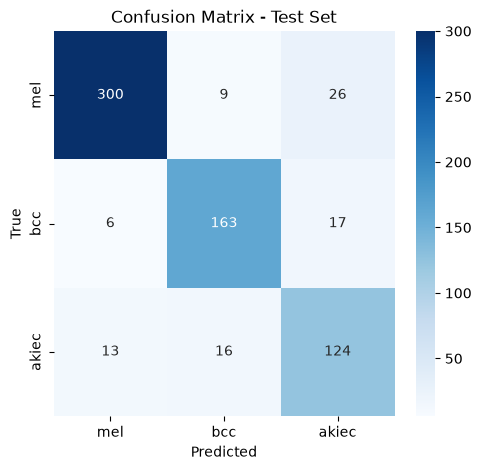

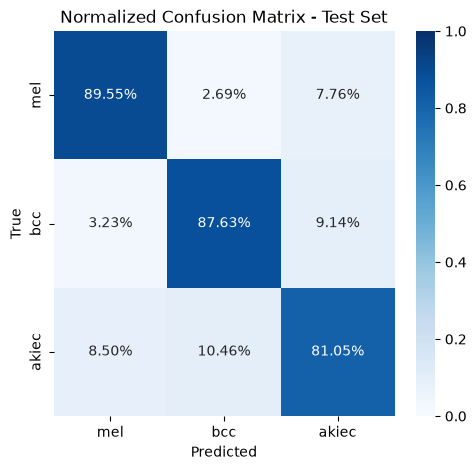

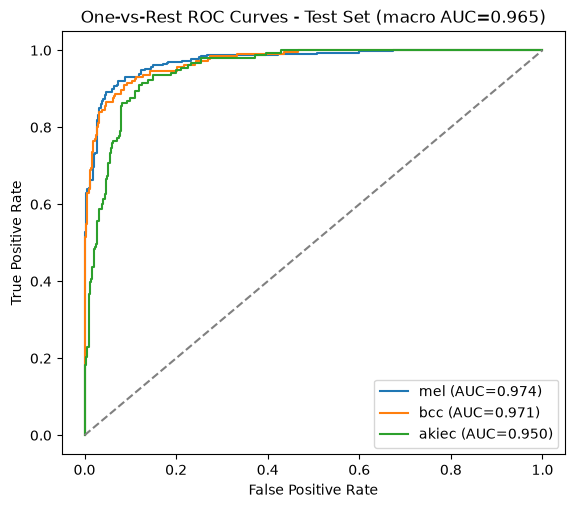

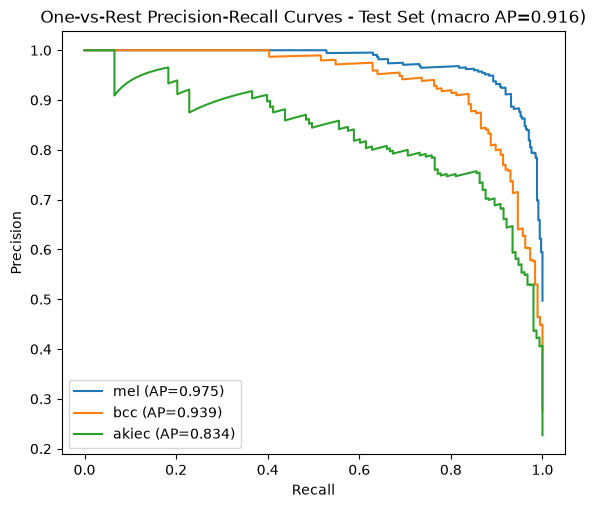

In [16]:
cm = confusion_matrix(test_labels, test_preds)
fig, ax = plt.subplots(figsize=(5.5, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=MALIGNANT_CLASSES,
            yticklabels=MALIGNANT_CLASSES, ax=ax)
ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title("Confusion Matrix - Test Set")
fig.savefig(CONFUSION_MATRICES_DIR / "confusion_matrix.png", bbox_inches="tight", dpi=150)
plt.show()

cm_normalized = cm.astype(float) / cm.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(5.5, 5))
sns.heatmap(cm_normalized, annot=True, fmt=".2%", cmap="Blues", xticklabels=MALIGNANT_CLASSES,
            yticklabels=MALIGNANT_CLASSES, ax=ax, vmin=0, vmax=1)
ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title("Normalized Confusion Matrix - Test Set")
fig.savefig(CONFUSION_MATRICES_DIR / "normalized_confusion_matrix.png", bbox_inches="tight", dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(6.5, 5.5))
for i, cls in enumerate(MALIGNANT_CLASSES):
    fpr, tpr, _ = roc_curve(test_labels_bin[:, i], test_probs[:, i])
    ax.plot(fpr, tpr, label=f"{cls} (AUC={roc_auc_score(test_labels_bin[:, i], test_probs[:, i]):.3f})")
ax.plot([0, 1], [0, 1], "--", color="grey")
ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate")
ax.set_title(f"One-vs-Rest ROC Curves - Test Set (macro AUC={metrics['roc_auc_macro_ovr']:.3f})")
ax.legend()
fig.savefig(ROC_PR_DIR / "roc_curve.png", bbox_inches="tight", dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(6.5, 5.5))
for i, cls in enumerate(MALIGNANT_CLASSES):
    precision_vals, recall_vals, _ = precision_recall_curve(test_labels_bin[:, i], test_probs[:, i])
    ap = average_precision_score(test_labels_bin[:, i], test_probs[:, i])
    ax.plot(recall_vals, precision_vals, label=f"{cls} (AP={ap:.3f})")
ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
ax.set_title(f"One-vs-Rest Precision-Recall Curves - Test Set (macro AP={metrics['pr_auc_macro_ovr']:.3f})")
ax.legend()
fig.savefig(ROC_PR_DIR / "precision_recall_curve.png", bbox_inches="tight", dpi=150)
plt.show()


## 17. Predictions Output

**Adapted schema**: `probability_benign`/`probability_malignant` (2 columns) become
`probability_mel`, `probability_bcc`, `probability_akiec` (3 columns). `predicted_label` is now
in `{0,1,2}` via `argmax`, not threshold-based. The verify-align-sort logic itself
(`finalize_and_save_predictions`) is otherwise identical to Stage 1 - unique `image_id`, exact
correspondence to the reference DataFrame, explicit merge-by-`image_id` (never row order), sort,
`RuntimeError` on any mismatch.

In [17]:
def finalize_and_save_predictions(predictions_df: pd.DataFrame, reference_df: pd.DataFrame, output_path: Path) -> pd.DataFrame:
    required_columns = {"image_id", "true_label", "predicted_label",
                         "probability_mel", "probability_bcc", "probability_akiec"}
    missing_columns = required_columns - set(predictions_df.columns)
    if missing_columns:
        raise RuntimeError(f"predictions file is missing required column(s): {missing_columns}")

    if predictions_df["image_id"].duplicated().any():
        dup_ids = predictions_df.loc[predictions_df["image_id"].duplicated(), "image_id"].tolist()
        raise RuntimeError(f"Duplicate image_id value(s) found in predictions: {dup_ids}")

    predicted_ids = set(predictions_df["image_id"])
    expected_ids = set(reference_df["image_id"])
    if predicted_ids != expected_ids:
        missing = expected_ids - predicted_ids
        extra = predicted_ids - expected_ids
        raise RuntimeError(
            f"Predictions do not correspond exactly to the reference metadata. "
            f"Missing {len(missing)} (e.g. {list(missing)[:5]}), extra {len(extra)} (e.g. {list(extra)[:5]})."
        )

    aligned = reference_df[["image_id"]].merge(predictions_df, on="image_id", how="left", validate="one_to_one")
    aligned = aligned.sort_values("image_id").reset_index(drop=True)

    aligned.to_csv(output_path, index=False)
    logger.info("Saved predictions (%d rows, verified + aligned + sorted by image_id) to %s", len(aligned), output_path)
    return aligned


predictions_df = pd.DataFrame({
    "image_id": test_ids,
    "true_label": test_labels.astype(int),
    "predicted_label": test_preds.astype(int),
    "probability_mel": test_probs[:, 0].astype(float),
    "probability_bcc": test_probs[:, 1].astype(float),
    "probability_akiec": test_probs[:, 2].astype(float),
})
predictions_df = finalize_and_save_predictions(predictions_df, test_df, PREDICTIONS_DIR / "predictions.csv")

val_predictions_df = pd.DataFrame({
    "image_id": val_ids,
    "true_label": val_labels.astype(int),
    "predicted_label": val_preds.astype(int),
    "probability_mel": val_probs[:, 0].astype(float),
    "probability_bcc": val_probs[:, 1].astype(float),
    "probability_akiec": val_probs[:, 2].astype(float),
})
val_predictions_df = finalize_and_save_predictions(val_predictions_df, val_df, PREDICTIONS_DIR / "val_predictions.csv")

predictions_df.head()


2026-07-25 11:40:01,653 | INFO | Saved predictions (674 rows, verified + aligned + sorted by image_id) to D:\SkinCancer_Project\outputs\multiclass\Multiclass_EfficientNetB3_Stage2_V1\predictions\predictions.csv
2026-07-25 11:40:01,661 | INFO | Saved predictions (673 rows, verified + aligned + sorted by image_id) to D:\SkinCancer_Project\outputs\multiclass\Multiclass_EfficientNetB3_Stage2_V1\predictions\val_predictions.csv


,image_id,true_label,predicted_label,probability_mel,probability_bcc,probability_akiec
0,ISIC_0000022,0,0,0.998968,0.000019,0.001013
1,ISIC_0000030,0,0,0.741117,0.164664,0.094218
2,ISIC_0000142,0,0,0.944528,0.052198,0.003275
3,ISIC_0000147,0,0,0.784616,0.214363,0.001021
4,ISIC_0000153,0,0,0.835404,0.007798,0.156798


## 18. Error Analysis

**Adapted**: True/False Positive/Negative is a binary-only concept and does not generalize to 3
classes. The multiclass-appropriate analogue used here: for each of the 3 true classes, a
"correct" category (predicted class matches true class) and a "misclassified" category (predicted
class differs) - 6 categories total, giving the same per-class error visibility Stage 1's 4
categories gave for 2 classes, via CSVs + image grids + stats, same as Stage 1.

In [18]:
predictions_df["true_class"] = predictions_df["true_label"].map(MALIGNANT_LABEL_NAMES)
predictions_df["predicted_class"] = predictions_df["predicted_label"].map(MALIGNANT_LABEL_NAMES)
predictions_df["category"] = np.where(
    predictions_df["true_label"] == predictions_df["predicted_label"],
    "correct_" + predictions_df["true_class"],
    "misclassified_" + predictions_df["true_class"],
)
path_by_id = dict(zip(test_df["image_id"], test_df["image_path"]))

category_stats = {}
for true_class in MALIGNANT_CLASSES:
    for kind in ["correct", "misclassified"]:
        category = f"{kind}_{true_class}"
        subset = predictions_df[predictions_df["category"] == category]
        subset.to_csv(ERROR_ANALYSIS_DIR / f"{category}.csv", index=False)

        category_stats[category] = {
            "count": int(len(subset)),
            "mean_confidence_in_true_class": (
                float(subset[f"probability_{true_class}"].mean()) if len(subset) else None
            ),
        }

        sample = subset.head(16)
        if len(sample) > 0:
            n_cols = 4
            n_rows = int(np.ceil(len(sample) / n_cols))
            fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 3, n_rows * 3))
            axes = np.atleast_1d(axes).flatten()
            for ax, (_, row) in zip(axes, sample.iterrows()):
                img_path = path_by_id.get(row["image_id"])
                try:
                    ax.imshow(Image.open(img_path).convert("RGB"))
                except Exception:
                    pass
                ax.set_title(f"{row['image_id']}\ntrue={row['true_class']} pred={row['predicted_class']}", fontsize=7)
                ax.axis("off")
            for ax in axes[len(sample):]:
                ax.axis("off")
            fig.suptitle(f"{category} - sample of {len(sample)} (of {len(subset)} total)")
            fig.tight_layout()
            fig.savefig(PLOTS_ERROR_ANALYSIS_DIR / f"{category}_grid.png", bbox_inches="tight", dpi=150)
            plt.close(fig)

with open(ERROR_ANALYSIS_DIR / "error_analysis_stats.json", "w") as f:
    json.dump(category_stats, f, indent=2)

logger.info("Error analysis category counts: %s", {k: v["count"] for k, v in category_stats.items()})
category_stats


2026-07-25 11:40:13,345 | INFO | Error analysis category counts: {'correct_mel': 300, 'misclassified_mel': 35, 'correct_bcc': 163, 'misclassified_bcc': 23, 'correct_akiec': 124, 'misclassified_akiec': 29}


{'correct_mel': {'count': 300,
  'mean_confidence_in_true_class': 0.9208862582842509},
 'misclassified_mel': {'count': 35,
  'mean_confidence_in_true_class': 0.22623640824375407},
 'correct_bcc': {'count': 163,
  'mean_confidence_in_true_class': 0.8968461249137949},
 'misclassified_bcc': {'count': 23,
  'mean_confidence_in_true_class': 0.1886255371019892},
 'correct_akiec': {'count': 124,
  'mean_confidence_in_true_class': 0.8557673373049305},
 'misclassified_akiec': {'count': 29,
  'mean_confidence_in_true_class': 0.25818873180783003}}

## 19. Run Summary

Same two-file pattern as every Stage 1 notebook: `metrics_summary.json` (full run summary) and
`run_config.json` (fully-resolved `CONFIG` alone).

In [19]:
metrics_summary = {
    "experiment_name": "Multiclass_EfficientNetB3_Stage2_V1",
    "stage": "stage2_malignant_subtype",
    "backbone": "EfficientNet-B3",
    "classes": MALIGNANT_CLASSES,
    "run_timestamp": RUN_TIMESTAMP,
    "best_epoch": best_state["epoch"],
    "best_val_auc_macro_ovr": best_state["val_auc"],
    "used_tta": CONFIG["use_tta"],
    "calibration_used": False,
    "test_metrics": metrics,
    "outputs_dir": str(OUTPUT_DIR),
}
with open(OUTPUT_DIR / "metrics_summary.json", "w") as f:
    json.dump(metrics_summary, f, indent=2, default=str)

config_to_save = {k: (str(v) if isinstance(v, Path) else v) for k, v in CONFIG.items()}
with open(OUTPUT_DIR / "run_config.json", "w") as f:
    json.dump(config_to_save, f, indent=2, default=str)

logger.info("=== Multiclass_EfficientNetB3_Stage2_V1 finished. Outputs saved to %s ===", OUTPUT_DIR)
metrics_summary


2026-07-25 11:40:13,505 | INFO | === Multiclass_EfficientNetB3_Stage2_V1 finished. Outputs saved to D:\SkinCancer_Project\outputs\multiclass\Multiclass_EfficientNetB3_Stage2_V1 ===


{'experiment_name': 'Multiclass_EfficientNetB3_Stage2_V1',
 'stage': 'stage2_malignant_subtype',
 'backbone': 'EfficientNet-B3',
 'classes': ['mel', 'bcc', 'akiec'],
 'run_timestamp': '20260725_111920',
 'best_epoch': 18,
 'best_val_auc_macro_ovr': 0.9605723044302671,
 'used_tta': True,
 'calibration_used': False,
 'test_metrics': {'accuracy': 0.870919881305638,
  'balanced_accuracy': 0.8607746634736921,
  'precision_macro': 0.8499917060429931,
  'recall_macro': 0.8607746634736921,
  'f1_macro': 0.8546963155570819,
  'roc_auc_macro_ovr': 0.9648090574440998,
  'pr_auc_macro_ovr': 0.9162610856341028},
 'outputs_dir': 'D:\\SkinCancer_Project\\outputs\\multiclass\\Multiclass_EfficientNetB3_Stage2_V1'}